<div dir="rtl" style="direction: rtl; text-align: right;">

# راهنمای آموزشی: بررسی و پیش‌بینی فروش نانوایی

در این تمرین از داده‌ی واقعی فروش یک نانوایی استفاده می‌کنیم. هر ردیف، درآمد یک گروه محصول در یک روز را نشان می‌دهد. ستون `Umsatz` **درآمد فروش** است، نه تعداد نان یا تعداد محصولات فروخته‌شده.

سه مدل را با سه هدف متفاوت بررسی می‌کنیم:

۱. **MLP:** پیش‌بینی درآمد یک گروه محصول با کمک فروش روزهای قبل و ویژگی‌های تقویمی؛
۲. **RBM:** پیدا کردن الگوهای تکراری در پنجره‌های ۱۴روزه‌ی فروش؛
۳. **Autoencoder:** فشرده‌سازی و بازسازی پنجره‌های ۱۴روزه و پیدا کردن پنجره‌هایی که بازسازی آن‌ها دشوارتر است.

این سه مدل قرار نیست یک خروجی یا یک معیار مشترک داشته باشند.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱. داده‌ی مورد استفاده

فایل اصلی `train.csv` شامل تاریخ، گروه محصول و درآمد روزانه است. شش گروه محصول عبارت‌اند از:

| کد | گروه محصول |
|---:|---|
| ۱ | نان |
| ۲ | رول و نان کوچک |
| ۳ | کروسان |
| ۴ | شیرینی و محصولات قنادی |
| ۵ | کیک |
| ۶ | نان فصلی |

منبع داده: [Bakery Sales Prediction Summer 2024 – Kaggle](https://www.kaggle.com/competitions/bakery-sales-prediction-summer-24/data)

برای اجرای راهنما، فایل `train.csv` را در پوشه‌ی `notebooks/data` قرار دهید. فایل‌های `wetter.csv` و `kiwo.csv` اختیاری‌اند؛ اگر موجود باشند، کد MLP می‌تواند از آن‌ها به‌عنوان ویژگی کمکی استفاده کند. برای اجرای اصلی پروژه به آن‌ها نیاز نیست.

</div>

In [1]:
# Install once if needed:
# %pip install -r ../requirements.txt

from copy import deepcopy
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import BernoulliRBM, MLPRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 2026
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

NumPy: 2.2.6
Pandas: 2.3.3
TensorFlow: 2.21.0


<div dir="rtl" style="direction: rtl; text-align: right;">

## ۲. تنظیمات اصلی

| تنظیم | مقدار | کاربرد |
|---|---:|---|
| طول پنجره | ۱۴ روز | ورودی RBM و Autoencoder |
| تقسیم داده | ۷۰٪ / ۱۵٪ / ۱۵٪ | آموزش / اعتبارسنجی / آزمون |
| ورودی RBM | ۱۴ روز × ۶ گروه × ۳ سطح | یادگیری الگوهای پنهان |
| واحدهای پنهان RBM | ۴ | نمایش فشرده‌تر و ساده‌تر |
| ورودی Autoencoder | ۱۴ روز × ۶ گروه = ۸۴ مقدار | بازسازی پنجره‌ی فروش |
| گلوگاه Autoencoder | ۱۲ واحد | فشرده‌سازی ورودی |

</div>

In [2]:
# Shared time-series settings
WINDOW = 14
TRAIN_SHARE = 0.70
VALIDATION_SHARE = 0.15

# MLP hyperparameters inspired by the reference neural-network notebook
MLP_HIDDEN_UNITS = (64, 32)
MLP_DROPOUT_RATE = 0.20
MLP_LEARNING_RATE = 0.001
MLP_BATCH_SIZE = 64
MLP_EPOCHS = 50
MLP_PATIENCE = 10

# RBM hyperparameters
RBM_HIDDEN_UNITS = 4
RBM_LEARNING_RATE = 0.02
RBM_BATCH_SIZE = 32
RBM_EPOCHS = 80

# Autoencoder hyperparameters
AE_HIDDEN_LAYERS = (32, 12, 32)
AE_LEARNING_RATE = 0.001
AE_ALPHA = 0.0005
AE_BATCH_SIZE = 32
AE_MAX_EPOCHS = 300
AE_PATIENCE = 25

print("Window for RBM and Autoencoder:", WINDOW, "days")
print("MLP hidden layers:", MLP_HIDDEN_UNITS)
print("MLP dropout rate:", MLP_DROPOUT_RATE)
print("RBM hidden units:", RBM_HIDDEN_UNITS)
print("Autoencoder hidden layers:", AE_HIDDEN_LAYERS)

Window for RBM and Autoencoder: 14 days
MLP hidden layers: (64, 32)
MLP dropout rate: 0.2
RBM hidden units: 4
Autoencoder hidden layers: (32, 12, 32)


<div dir="rtl" style="direction: rtl; text-align: right;">

## ۳. بارگذاری و بررسی اولیه

فایل اصلی رقابت در قالب طولی است: هر سطر، درآمد یک گروه محصول در یک تاریخ را ثبت می‌کند. ابتدا نوع ستون‌ها، بازه‌ی زمانی، تعداد گروه‌ها، مقدارهای خالی و ردیف‌های تکراری را بررسی می‌کنیم.

</div>

In [3]:
DATA_CANDIDATES = [
    Path("data/train.csv"),
    Path("../data/train.csv"),
    Path("train.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "train.csv was not found. Download the direct GitHub mirror or the official Kaggle file "
        "and place it at notebooks/data/train.csv. See the project README."
    )

raw = pd.read_csv(DATA_PATH)
required = {"Datum", "Warengruppe", "Umsatz"}
missing_columns = required.difference(raw.columns)
if missing_columns:
    raise ValueError(
        f"Unexpected dataset schema. Missing {sorted(missing_columns)}. "
        f"Columns found: {list(raw.columns)}"
    )

raw["Datum"] = pd.to_datetime(raw["Datum"], errors="coerce")
raw["Warengruppe"] = pd.to_numeric(raw["Warengruppe"], errors="coerce")
raw["Umsatz"] = pd.to_numeric(raw["Umsatz"], errors="coerce")
raw = raw.dropna(subset=["Datum", "Warengruppe", "Umsatz"]).copy()
raw["Warengruppe"] = raw["Warengruppe"].astype(int)
raw = raw[raw["Warengruppe"].isin([1, 2, 3, 4, 5, 6])].copy()

print("File:", DATA_PATH)
print("Rows:", len(raw))
print("Date range:", raw["Datum"].min().date(), "to", raw["Datum"].max().date())
print("Product groups:", sorted(raw["Warengruppe"].unique()))
print("Duplicate date-group rows:", raw.duplicated(["Datum", "Warengruppe"]).sum())
display(raw.head())
display(raw[["Datum", "Warengruppe", "Umsatz"]].isna().sum().to_frame("missing values"))

File: train.csv
Rows: 9334
Date range: 2013-07-01 to 2018-07-31
Product groups: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Duplicate date-group rows: 0


,id,Datum,Warengruppe,Umsatz
0,1307011,2013-07-01,1,148.828353
1,1307021,2013-07-02,1,159.793757
2,1307031,2013-07-03,1,111.885594
3,1307041,2013-07-04,1,168.864941
4,1307051,2013-07-05,1,171.280754


,missing values
Datum,0
Warengruppe,0
Umsatz,0


<div dir="rtl" style="direction: rtl; text-align: right;">

**تفسیر خروجی:**

- بازه‌ی زمانی باید با توضیح منبع داده هم‌خوان باشد؛ اگر چند روز بیشتر دیده نمی‌شود، احتمالاً فایل اشتباهی انتخاب شده است.
- باید هر شش گروه محصول وجود داشته باشند.
- درآمد باید عددی باشد.
- تکرار یک تاریخ و گروه را بررسی می‌کنیم؛ در تبدیل بعدی، ردیف‌های تکراری با هم جمع می‌شوند.
- مقدار خالی را بی‌دلیل صفر نکنید؛ «فروش صفر» با «ثبت نشدن داده» یکسان نیست.

</div>

In [4]:
GROUP_NAMES = {
    1: "Bread",
    2: "Rolls",
    3: "Croissant",
    4: "Confectionery",
    5: "Cake",
    6: "Seasonal bread",
}

wide = raw.pivot_table(
    index="Datum",
    columns="Warengruppe",
    values="Umsatz",
    aggfunc="sum",
).sort_index()

required_groups = list(GROUP_NAMES)
absent = sorted(set(required_groups).difference(wide.columns))
if absent:
    raise ValueError(f"Missing product groups in train.csv: {absent}")

wide = wide[required_groups].rename(columns=GROUP_NAMES)

# Keep the complete calendar so missing dates stay visible in plots.
calendar = pd.date_range(raw["Datum"].min(), raw["Datum"].max(), freq="D")
wide = wide.reindex(calendar)
wide.index.name = "date"

# Seasonal bread is a seasonal product. For this exercise, a missing
# seasonal-bread row is treated as zero recorded seasonal-bread revenue.
# Missing values in the other groups are NOT automatically changed to zero.
wide["Seasonal bread"] = wide["Seasonal bread"].fillna(0.0)

daily = wide.copy()
regular_groups = [name for name in daily.columns if name != "Seasonal bread"]
days_without_regular_records = daily[regular_groups].isna().all(axis=1)
days_with_any_regular_missing = daily[regular_groups].isna().any(axis=1)

print("Calendar days:", len(daily))
print("Days with no record for the regular product groups:", int(days_without_regular_records.sum()))
print("Days with at least one missing regular product group:", int(days_with_any_regular_missing.sum()))
print("Missing values by product group:")
display(daily.isna().sum().to_frame("missing dates"))
display(daily.describe().T.round(2))

Calendar days: 1857
Days with no record for the regular product groups: 38
Days with at least one missing regular product group: 91
Missing values by product group:


,missing dates
Warengruppe,
Bread,38
Rolls,38
Croissant,38
Confectionery,91
Cake,38
Seasonal bread,0


,count,mean,std,min,25%,50%,75%,max
Warengruppe,,,,,,,,
Bread,1819.0,122.14,40.30,23.11,96.44,120.05,144.26,416.79
Rolls,1819.0,402.50,139.66,175.00,289.05,370.83,492.84,1203.43
Croissant,1819.0,163.34,75.58,37.74,105.59,142.81,201.95,565.94
Confectionery,1766.0,87.95,35.32,27.43,66.02,79.99,98.35,430.50
Cake,1819.0,276.80,99.47,121.49,228.97,265.96,307.62,1879.46
Seasonal bread,1857.0,10.52,27.53,0.00,0.00,0.00,0.00,172.87


<div dir="rtl" style="direction: rtl; text-align: right;">

## ۴. تبدیل داده به شش سری زمانی هم‌تراز

هر تاریخ یک سطر و هر گروه محصول یک ستون می‌شود:

[
X_t = [Bread_t, Rolls_t, Croissant_t, Confectionery_t, Cake_t, SeasonalBread_t]
]

روزهایی را که حداقل یک گروه در آن‌ها ثبت نشده کنار می‌گذاریم و بعد فقط پنجره‌هایی را می‌سازیم که شامل ۱۴ روز تقویمیِ پیوسته باشند. این تصمیم محافظه‌کارانه است: مقدار ساختگی تولید نمی‌کنیم و روز گمشده را معادل فروش صفر نمی‌گیریم.

</div>

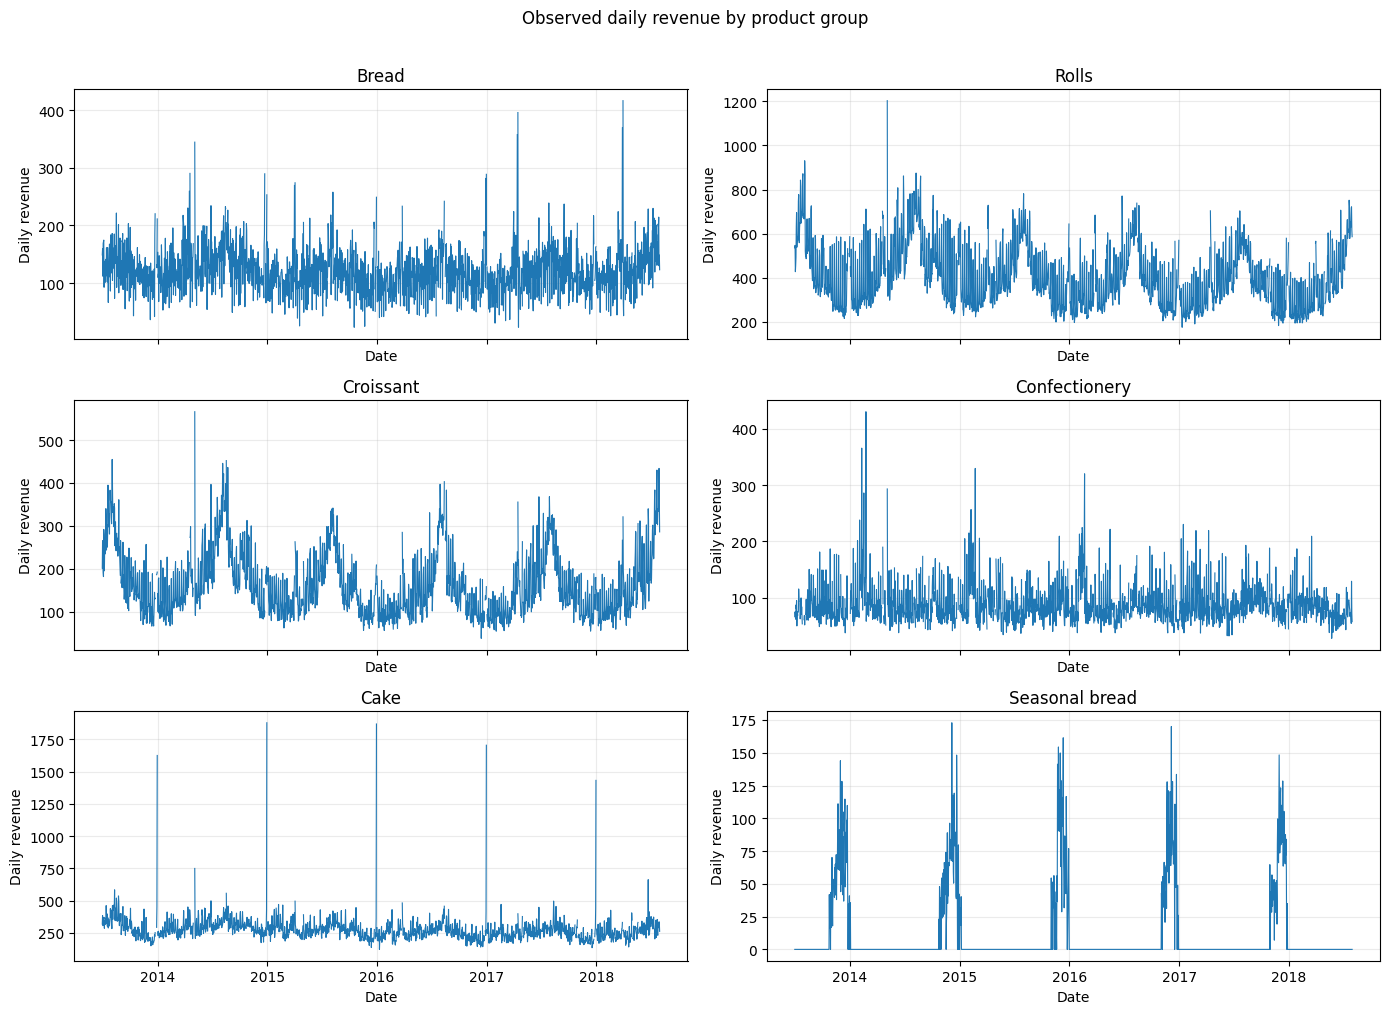

,count,mean,std,min,25%,50%,75%,max
Warengruppe,,,,,,,,
Bread,1819.0,122.14,40.30,23.11,96.44,120.05,144.26,416.79
Rolls,1819.0,402.50,139.66,175.00,289.05,370.83,492.84,1203.43
Croissant,1819.0,163.34,75.58,37.74,105.59,142.81,201.95,565.94
Confectionery,1766.0,87.95,35.32,27.43,66.02,79.99,98.35,430.50
Cake,1819.0,276.80,99.47,121.49,228.97,265.96,307.62,1879.46
Seasonal bread,1857.0,10.52,27.53,0.00,0.00,0.00,0.00,172.87


In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
for ax, column in zip(axes.ravel(), daily.columns):
    ax.plot(daily.index, daily[column], linewidth=0.8)
    ax.set_title(column)
    ax.set_ylabel("Daily revenue")
    ax.set_xlabel("Date")
plt.suptitle("Observed daily revenue by product group", y=1.01)
plt.tight_layout()
plt.show()

display(daily.describe().T.round(2))

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح نمودار

در این نسخه تمام تاریخ‌ها روی محور زمان حفظ شده‌اند. نبودن داده در گروه‌های غیر فصلی به شکل فاصله در خط دیده می‌شود و خط از روی آن فاصله عبور نمی‌کند. گروه نان فصلی در روزهای خارج از فصل با درآمد صفر نمایش داده می‌شود؛ این فرض در کد مشخص شده است.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

### تفسیر نمودار فروش روزانه

- هر پنل مربوط به یک گروه محصول است؛ مقدار درآمد گروه‌ها با یکدیگر برابر نیست.
- در گروه «نان فصلی»، مقدار صفر در خارج از فصل فروش یک فرض روشن در این تمرین است.
- اگر برای گروه‌های دیگر داده‌ای ثبت نشده باشد، نمودار در آن تاریخ خط را قطع می‌کند؛ این بخش را نباید به‌عنوان فروش ثابت یا صفر تفسیر کرد.
- قله‌ها ممکن است فروش واقعی در یک روز خاص باشند و لزوماً خطای ثبت داده نیستند.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۵. ساخت پنجره‌ی زمانی برای RBM و Autoencoder

برای RBM و Autoencoder هر نمونه از ۱۴ روز متوالی و شش گروه محصول ساخته می‌شود:

[
14 \times 6 = 84
]

MLP از این پنجره‌ی تخت‌شده استفاده نمی‌کند. در بخش MLP، داده را در قالب اصلی تاریخ × گروه محصول نگه می‌داریم و ویژگی‌های lag را مستقیماً از فروش قبلی همان گروه می‌سازیم. این کار به مدل اجازه می‌دهد اثر فروش روز قبل و روز مشابه هفته‌ی قبل را جداگانه یاد بگیرد.

</div>

In [6]:
values = daily.to_numpy(dtype=float)
date_values = daily.index.to_numpy()
n_days = len(daily)

train_day_end = int(n_days * TRAIN_SHARE)
validation_day_end = int(n_days * (TRAIN_SHARE + VALIDATION_SHARE))

def make_windows(start_pos, stop_pos):
    windows, window_end_dates = [], []

    # stop_pos is exclusive; every window must remain inside this split.
    for end_pos in range(start_pos + WINDOW, stop_pos + 1):
        window_start = end_pos - WINDOW
        context_dates = date_values[window_start:end_pos]
        window_values = values[window_start:end_pos]

        if not np.all(np.diff(context_dates) == np.timedelta64(1, "D")):
            continue
        if not np.isfinite(window_values).all():
            continue

        windows.append(window_values)
        window_end_dates.append(pd.Timestamp(date_values[end_pos - 1]))

    if not windows:
        return np.empty((0, WINDOW, values.shape[1])), pd.DatetimeIndex([])

    return np.asarray(windows, dtype=float), pd.DatetimeIndex(window_end_dates)

X_windows_train, train_window_dates = make_windows(0, train_day_end)
X_windows_val, val_window_dates = make_windows(train_day_end, validation_day_end)
X_windows_test, test_window_dates = make_windows(validation_day_end, n_days)

if min(len(X_windows_train), len(X_windows_val), len(X_windows_test)) == 0:
    raise ValueError("Not enough complete 14-day windows in one of the time splits.")

X_windows = np.concatenate([X_windows_train, X_windows_val, X_windows_test], axis=0)
target_dates = train_window_dates.append(val_window_dates).append(test_window_dates)

train_idx = np.arange(len(X_windows_train))
val_idx = np.arange(len(X_windows_train), len(X_windows_train) + len(X_windows_val))
test_idx = np.arange(len(X_windows_train) + len(X_windows_val), len(X_windows))

print("Train windows:", X_windows_train.shape)
print("Validation windows:", X_windows_val.shape)
print("Test windows:", X_windows_test.shape)
print("Window shape:", X_windows.shape[1:])
print("Total valid windows:", len(X_windows))

assert X_windows.shape[1:] == (WINDOW, 6)

Train windows: (746, 14, 6)
Validation windows: (221, 14, 6)
Test windows: (197, 14, 6)
Window shape: (14, 6)
Total valid windows: 1164


<div dir="rtl" style="direction: rtl; text-align: right;">

## ۶. تقسیم زمانی داده‌ها

برای جلوگیری از نشت اطلاعات، ابتدا تقویم را به سه بازه‌ی زمانی جدا تقسیم می‌کنیم:

- ۷۰٪ ابتدایی برای آموزش؛
- ۱۵٪ بعدی برای اعتبارسنجی؛
- ۱۵٪ انتهایی برای آزمون.

سپس پنجره‌های ۱۴روزه را **داخل هر بازه به‌صورت جداگانه** می‌سازیم. بنابراین هیچ پنجره‌ی آموزش با پنجره‌ی اعتبارسنجی یا آزمون روز مشترک ندارد.

</div>

**نکته درباره‌ی MLP:** این مدل یک روز را با استفاده از فروش روزهای قبل پیش‌بینی می‌کند. ویژگی‌های lag فقط از تاریخ‌های قبلی همان گروه محصول ساخته می‌شوند.

In [7]:
print(
    "Train:",
    len(train_idx),
    target_dates[train_idx[0]].date(),
    "to",
    target_dates[train_idx[-1]].date(),
)
print(
    "Validation:",
    len(val_idx),
    target_dates[val_idx[0]].date(),
    "to",
    target_dates[val_idx[-1]].date(),
)
print(
    "Test:",
    len(test_idx),
    target_dates[test_idx[0]].date(),
    "to",
    target_dates[test_idx[-1]].date(),
)
print("Each 14-day window belongs entirely to one split.")

Train: 746 2013-08-19 to 2017-01-19
Validation: 221 2017-02-02 to 2017-10-22
Test: 197 2017-11-14 to 2018-07-31
Each 14-day window belongs entirely to one split.


<div dir="rtl" style="direction: rtl; text-align: right;">

# بخش اول: MLP برای پیش‌بینی فروش

## ۷. ویژگی‌سازی بر اساس روش مرجع

در روش مرجع، هر ردیف مربوط به یک تاریخ و یک گروه محصول است. شبکه فقط یک عدد را پیش‌بینی می‌کند: درآمد همان گروه در همان تاریخ.

ویژگی‌های کلیدی این مدل:
- درآمد دقیقاً یک روز قبل همان گروه؛
- درآمد دقیقاً هفت روز قبل همان گروه؛
- میانگین درآمدهای ثبت‌شده در هفت روز تقویمی گذشته؛
- شناسه‌ی گروه محصول به‌صورت one-hot؛
- روز هفته، ماه و چرخه‌ی سال؛
- در صورت وجود فایل‌های اختیاری، دما، پوشش ابر، سرعت باد و رویداد Kieler Woche.

تفاوت مهم با پرکردن مقدارهای خالی با صفر: اگر فروش روز قبل یا هفت روز قبل ثبت نشده باشد، آن نمونه را کنار می‌گذاریم. نبودن رکورد لزوماً به معنی فروش صفر نیست.

</div>

In [8]:
mlp_base = (
    raw.groupby(["Datum", "Warengruppe"], as_index=False)["Umsatz"]
    .sum()
    .sort_values(["Datum", "Warengruppe"])
    .reset_index(drop=True)
)

mlp_frame = mlp_base.copy()
sales_lookup = mlp_base[["Datum", "Warengruppe", "Umsatz"]].copy()

# Join exact calendar-day lags, so a closed/missing day is not silently
# interpreted as the previous available record.
for lag_days in range(1, 8):
    shifted = sales_lookup.copy()
    shifted["Datum"] = shifted["Datum"] + pd.Timedelta(days=lag_days)
    shifted = shifted.rename(columns={"Umsatz": f"sales_lag_{lag_days}"})
    mlp_frame = mlp_frame.merge(
        shifted,
        on=["Datum", "Warengruppe"],
        how="left",
        validate="one_to_one",
    )

lag_columns = [f"sales_lag_{day}" for day in range(1, 8)]
mlp_frame["Umsatz_lag_1"] = mlp_frame["sales_lag_1"]
mlp_frame["Umsatz_lag_7"] = mlp_frame["sales_lag_7"]
mlp_frame["Umsatz_rolling_7"] = mlp_frame[lag_columns].mean(axis=1)

# Optional daily weather features.
def find_optional_file(filename):
    candidates = [
        Path("data") / filename,
        Path("../data") / filename,
        Path(filename),
    ]
    return next((path for path in candidates if path.exists()), None)

weather_feature_columns = []
weather_path = find_optional_file("wetter.csv")

if weather_path is not None:
    weather = pd.read_csv(weather_path)
    if "Datum" not in weather.columns:
        raise ValueError("wetter.csv must contain a Datum column.")

    weather["Datum"] = pd.to_datetime(weather["Datum"], errors="coerce")
    weather = weather.dropna(subset=["Datum"]).drop_duplicates("Datum", keep="last")

    weather_rename = {
        "Bewoelkung": "WeatherCloudCover",
        "Temperatur": "WeatherTemperature",
        "Windgeschwindigkeit": "WeatherWindSpeed",
    }
    available_weather = [name for name in weather_rename if name in weather.columns]
    weather = weather[["Datum"] + available_weather].rename(columns=weather_rename)

    for column in weather.columns:
        if column != "Datum":
            weather[column] = pd.to_numeric(weather[column], errors="coerce")

    mlp_frame = mlp_frame.merge(
        weather,
        on="Datum",
        how="left",
        validate="many_to_one",
    )
    weather_feature_columns = [weather_rename[name] for name in available_weather]
    print("Weather features loaded:", weather_feature_columns)
else:
    print("Optional wetter.csv not found; continuing without weather features.")

# Optional Kieler Woche event indicator.
kiwo_path = find_optional_file("kiwo.csv")
if kiwo_path is not None:
    kiwo = pd.read_csv(kiwo_path)
    if "Datum" not in kiwo.columns:
        raise ValueError("kiwo.csv must contain a Datum column.")

    kiwo["Datum"] = pd.to_datetime(kiwo["Datum"], errors="coerce")
    kiwo = kiwo.dropna(subset=["Datum"])[["Datum"]].drop_duplicates()
    kiwo["KielerWoche"] = 1.0

    mlp_frame = mlp_frame.merge(
        kiwo,
        on="Datum",
        how="left",
        validate="many_to_one",
    )
    mlp_frame["KielerWoche"] = mlp_frame["KielerWoche"].fillna(0.0)
    kiwo_feature_columns = ["KielerWoche"]
    print("Kieler Woche event feature loaded.")
else:
    kiwo_feature_columns = []
    print("Optional kiwo.csv not found; continuing without event features.")

# Calendar features: Monday-Thursday are grouped, as in the reference workflow.
weekday_number = mlp_frame["Datum"].dt.dayofweek
weekday_label = np.select(
    [weekday_number == 4, weekday_number == 5, weekday_number == 6],
    ["Friday", "Saturday", "Sunday"],
    default="Weekday",
)

group_series = pd.Series(
    pd.Categorical(mlp_frame["Warengruppe"], categories=[1, 2, 3, 4, 5, 6]),
    index=mlp_frame.index,
)
weekday_series = pd.Series(
    pd.Categorical(
        weekday_label,
        categories=["Weekday", "Friday", "Saturday", "Sunday"],
    ),
    index=mlp_frame.index,
)
month_series = pd.Series(
    pd.Categorical(mlp_frame["Datum"].dt.month, categories=list(range(1, 13))),
    index=mlp_frame.index,
)

group_dummies = pd.get_dummies(group_series, prefix="group", dtype=float)
weekday_dummies = pd.get_dummies(weekday_series, prefix="weekday", dtype=float)
month_dummies = pd.get_dummies(month_series, prefix="month", dtype=float)

day_of_year = mlp_frame["Datum"].dt.dayofyear
mlp_frame["YearSin"] = np.sin(2 * np.pi * day_of_year / 365.25)
mlp_frame["YearCos"] = np.cos(2 * np.pi * day_of_year / 365.25)

mlp_frame = pd.concat(
    [mlp_frame, group_dummies, weekday_dummies, month_dummies],
    axis=1,
)

MLP_FEATURES = (
    ["Umsatz_lag_1", "Umsatz_lag_7", "Umsatz_rolling_7", "YearSin", "YearCos"]
    + group_dummies.columns.tolist()
    + weekday_dummies.columns.tolist()
    + month_dummies.columns.tolist()
    + weather_feature_columns
    + kiwo_feature_columns
)

rows_before_lag_filter = len(mlp_frame)
mlp_frame = mlp_frame.dropna(
    subset=["Umsatz_lag_1", "Umsatz_lag_7", "Umsatz_rolling_7"]
).copy()

# Split by unique dates so all product groups from one date stay in one split.
mlp_unique_dates = np.sort(mlp_frame["Datum"].unique())
mlp_train_end = int(len(mlp_unique_dates) * TRAIN_SHARE)
mlp_validation_end = int(
    len(mlp_unique_dates) * (TRAIN_SHARE + VALIDATION_SHARE)
)

if mlp_train_end < 30 or mlp_validation_end <= mlp_train_end or mlp_validation_end >= len(mlp_unique_dates):
    raise ValueError("Not enough dates for the requested chronological MLP split.")

mlp_train_last_date = pd.Timestamp(mlp_unique_dates[mlp_train_end - 1])
mlp_validation_last_date = pd.Timestamp(mlp_unique_dates[mlp_validation_end - 1])

mlp_train = mlp_frame[mlp_frame["Datum"] <= mlp_train_last_date].copy()
mlp_val = mlp_frame[
    (mlp_frame["Datum"] > mlp_train_last_date)
    & (mlp_frame["Datum"] <= mlp_validation_last_date)
].copy()
mlp_test = mlp_frame[mlp_frame["Datum"] > mlp_validation_last_date].copy()

print("MLP rows before lag filtering:", rows_before_lag_filter)
print("MLP rows after lag filtering:", len(mlp_frame))
print("MLP feature count:", len(MLP_FEATURES))
print("Train:", len(mlp_train), mlp_train["Datum"].min().date(), "to", mlp_train["Datum"].max().date())
print("Validation:", len(mlp_val), mlp_val["Datum"].min().date(), "to", mlp_val["Datum"].max().date())
print("Test:", len(mlp_test), mlp_test["Datum"].min().date(), "to", mlp_test["Datum"].max().date())

display(mlp_frame[["Datum", "Warengruppe", "Umsatz", "Umsatz_lag_1", "Umsatz_lag_7", "Umsatz_rolling_7"]].head(10))
display(pd.Series(MLP_FEATURES, name="MLP input features").to_frame())

Weather features loaded: ['WeatherCloudCover', 'WeatherTemperature', 'WeatherWindSpeed']
Kieler Woche event feature loaded.
MLP rows before lag filtering: 9334
MLP rows after lag filtering: 8880
MLP feature count: 31
Train: 6197 2013-07-08 to 2017-01-20
Validation: 1315 2017-01-21 to 2017-10-19
Test: 1368 2017-10-20 to 2018-07-31


,Datum,Warengruppe,Umsatz,Umsatz_lag_1,Umsatz_lag_7,Umsatz_rolling_7
35,2013-07-08,1,135.500244,92.637755,148.828353,146.834788
36,2013-07-08,2,538.529250,695.255730,535.856285,540.688653
37,2013-07-08,3,195.158794,279.665939,201.198426,231.467904
38,2013-07-08,4,49.500024,94.603902,65.890169,76.171047
39,2013-07-08,5,285.233382,370.209601,317.475875,343.233014
40,2013-07-09,1,136.048383,135.500244,159.793757,144.930772
41,2013-07-09,2,585.957265,538.529250,546.780787,541.070506
42,2013-07-09,3,245.808339,195.158794,265.261254,230.605100
43,2013-07-09,4,75.208998,49.500024,74.543917,73.829598
44,2013-07-09,5,342.089346,285.233382,383.628682,338.626944


,MLP input features
0,Umsatz_lag_1
1,Umsatz_lag_7
2,Umsatz_rolling_7
3,YearSin
4,YearCos
5,group_1
6,group_2
7,group_3
8,group_4
9,group_5


<div dir="rtl" style="direction: rtl; text-align: right;">

## ۸. معماری شبکه‌ی عصبی

ساختار شبکه مطابق مدل مرجع است:

[
N_{features} \rightarrow 64 \rightarrow 32 \rightarrow 1
]

بعد از هر لایه‌ی Dense از ReLU، Batch Normalization و Dropout با نرخ ۰٫۲ استفاده می‌شود. لایه‌ی خروجی یک نورون با فعال‌ساز خطی دارد؛ چون هدف، پیش‌بینی یک مقدار پیوسته‌ی درآمد است.

هر نمونه یک گروه محصول و یک تاریخ دارد. بنابراین مدل برای هر ردیف فقط **یک مقدار درآمد** تولید می‌کند، نه شش خروجی هم‌زمان.

ویژگی‌ها را با StandardScaler استاندارد می‌کنیم؛ scaler فقط روی train fit می‌شود. هدف را در واحد اصلی درآمد نگه می‌داریم تا MSE و MAE معنای مستقیم‌تری داشته باشند.

</div>

In [9]:
X_train_raw = mlp_train[MLP_FEATURES].copy()
X_val_raw = mlp_val[MLP_FEATURES].copy()
X_test_raw = mlp_test[MLP_FEATURES].copy()

y_train = mlp_train["Umsatz"].to_numpy(dtype=float)
y_val = mlp_val["Umsatz"].to_numpy(dtype=float)
y_test = mlp_test["Umsatz"].to_numpy(dtype=float)

# Impute optional weather gaps using training medians only.
for column in weather_feature_columns:
    fill_value = X_train_raw[column].median()
    if pd.isna(fill_value):
        fill_value = 0.0

    X_train_raw.loc[:, column] = X_train_raw[column].fillna(fill_value)
    X_val_raw.loc[:, column] = X_val_raw[column].fillna(fill_value)
    X_test_raw.loc[:, column] = X_test_raw[column].fillna(fill_value)

x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train_raw).astype(np.float32)
X_val_scaled = x_scaler.transform(X_val_raw).astype(np.float32)
X_test_scaled = x_scaler.transform(X_test_raw).astype(np.float32)

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(MLP_HIDDEN_UNITS[0], activation="relu"),
    BatchNormalization(),
    Dropout(MLP_DROPOUT_RATE),

    Dense(MLP_HIDDEN_UNITS[1], activation="relu"),
    BatchNormalization(),
    Dropout(MLP_DROPOUT_RATE),

    Dense(1),
])

model.compile(
    optimizer=Adam(learning_rate=MLP_LEARNING_RATE),
    loss="mse",
    metrics=["mae"],
)

model.summary()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=MLP_PATIENCE,
    restore_best_weights=True,
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=MLP_EPOCHS,
    batch_size=MLP_BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1,
)

mlp_train_loss = history.history["loss"]
mlp_val_loss = history.history["val_loss"]
best_mlp_epoch = int(np.argmin(mlp_val_loss) + 1)

print("Best validation epoch:", best_mlp_epoch)
print("Epochs executed:", len(mlp_train_loss))
print("Best validation MSE:", round(float(np.min(mlp_val_loss)), 3))
print("Best validation MAE:", round(float(np.min(history.history["val_mae"])), 3))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,545 (17.75 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 66510.3438 - mae: 211.9931 - val_loss: 57361.9727 - val_mae: 205.5863
Epoch 2/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 64126.5664 - mae: 210.4834 - val_loss: 55492.6484 - val_mae: 206.3874
Epoch 3/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 61243.8438 - mae: 207.7307 - val_loss: 52473.2891 - val_mae: 202.9513
Epoch 4/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 57816.9883 - mae: 203.7149 - val_loss: 49543.6680 - val_mae: 199.0053
Epoch 5/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 53764.2812 - mae: 198.4726 - val_loss: 46218.5117 - val_mae: 194.1918
Epoch 6/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 49504.0039 - mae: 192.3018 - val_loss: 42737.5312 - val_mae: 188.7597
Epoch 7/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 44876.3789 - mae: 185.0656 - val_loss: 39105.7773 - val_mae: 182.5064
Epoch 8/50
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 40191.1406 - mae: 176.8863 - val_loss: 35147.2

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۹. تفسیر نمودار loss در MLP

منحنی train خطای مدل روی داده‌ی آموزش و منحنی validation خطای آن روی تاریخ‌های بعدی را نشان می‌دهد. چون خروجی در واحد درآمد است، loss از نوع MSE و واحد آن «مربع واحد درآمد» است.

| شکل نمودار | برداشت |
|---|---|
| هر دو منحنی کاهش پیدا کنند | نشانه‌ی یادگیری مفید |
| train کاهش یابد ولی validation افزایش یابد | احتمال بیش‌برازش |
| هر دو از ابتدا بالا و تقریباً ثابت باشند | احتمال کم‌برازش یا نرخ یادگیری نامناسب |
| validation نوسان شدید داشته باشد | نرخ یادگیری زیاد یا آموزش ناپایدار |
| validation مدتی ثابت بماند | epochهای بیشتر احتمالاً سود کمی دارند |

خطوط کم‌رنگ، مقدار خام هر epoch هستند. میانگین متحرک پنج epoch فقط برای خواناتر شدن روند رسم شده است. EarlyStopping آموزش را متوقف می‌کند وقتی validation loss برای چند epoch بهتر نشود و بهترین وزن‌ها را بازیابی می‌کند.

</div>

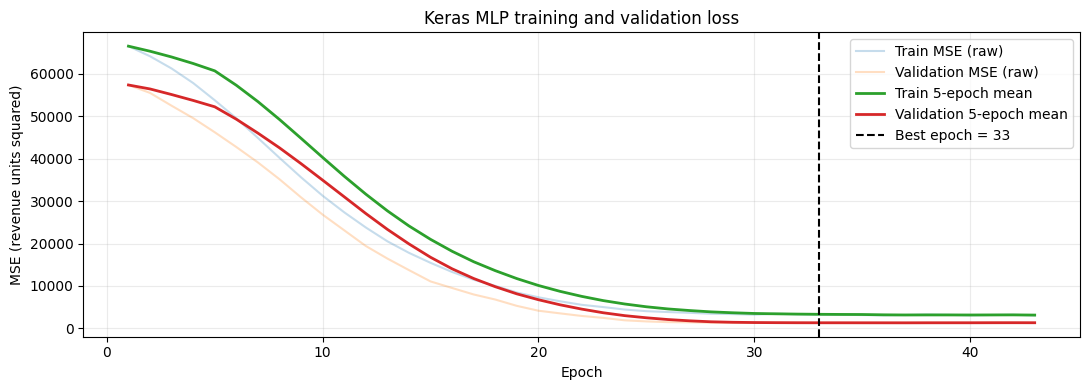

In [10]:
epochs = np.arange(1, len(mlp_train_loss) + 1)

train_smooth = pd.Series(mlp_train_loss).rolling(5, min_periods=1).mean()
val_smooth = pd.Series(mlp_val_loss).rolling(5, min_periods=1).mean()

plt.figure(figsize=(11, 4))
plt.plot(epochs, mlp_train_loss, alpha=0.25, label="Train MSE (raw)")
plt.plot(epochs, mlp_val_loss, alpha=0.25, label="Validation MSE (raw)")
plt.plot(epochs, train_smooth, linewidth=2, label="Train 5-epoch mean")
plt.plot(epochs, val_smooth, linewidth=2, label="Validation 5-epoch mean")
plt.axvline(best_mlp_epoch, linestyle="--", color="black", label=f"Best epoch = {best_mlp_epoch}")
plt.xlabel("Epoch")
plt.ylabel("MSE (revenue units squared)")
plt.title("Keras MLP training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح نمودار خطای MLP

خطوط کم‌رنگ، خطای هر epoch و خطوط پررنگ، میانگین متحرک پنج epoch هستند. کاهش هر دو خط نشان می‌دهد مدل در حال یادگیری است. اگر خط اعتبارسنجی مدتی ثابت بماند یا افزایش یابد، ادامه‌ی آموزش احتمالاً کمکی نمی‌کند. پایین‌تر بودن validation از train همیشه اشتباه نیست؛ در این مدل Dropout هنگام آموزش فعال است و هنگام اعتبارسنجی غیرفعال می‌شود.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱۰. ارزیابی MLP در برابر baseline

پیش‌بینی را با یک خط مبنای ساده مقایسه می‌کنیم: **درآمد همان گروه محصول در همان تاریخِ هفته‌ی قبل**. این مقدار همان ویژگی lag هفت‌روزه است و یک معیار مقایسه‌ی معنادار برای چرخه‌ی هفتگی فروش محسوب می‌شود.

- **MAE:** میانگین قدرمطلق خطا؛ کمتر بهتر است و واحد آن همان واحد درآمد است.
- **RMSE:** جذر میانگین مربع خطا؛ کمتر بهتر است و خطاهای بزرگ را بیشتر جریمه می‌کند.
- **R²:** هرچه به ۱ نزدیک‌تر بهتر؛ مقدار منفی یعنی مدل از پیش‌بینی میانگین همان مجموعه نیز بدتر بوده است.
- **MAPE:** میانگین خطای درصدی؛ کمتر بهتر است. ردیف‌هایی با مقدار واقعی صفر از محاسبه حذف می‌شوند تا تقسیم بر صفر رخ ندهد.

معیارها را هم برای هر گروه محصول و هم برای کل ردیف‌های آزمون گزارش می‌کنیم. عملکرد مدل را با baseline مقایسه کنید؛ پایین بودن loss به‌تنهایی کافی نیست.

</div>

In [11]:
def calculate_regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    nonzero = np.abs(y_true) > 1e-8

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MAPE_percent": (
            np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100
            if nonzero.any() else np.nan
        ),
    }

mlp_test_prediction = model.predict(X_test_scaled, verbose=0).reshape(-1)
baseline_prediction = mlp_test["Umsatz_lag_7"].to_numpy(dtype=float)
y_test_actual = mlp_test["Umsatz"].to_numpy(dtype=float)

metric_rows = []
for model_name, prediction in [
    ("MLP", mlp_test_prediction),
    ("Previous-week baseline", baseline_prediction),
]:
    for group_code, group_name in GROUP_NAMES.items():
        group_mask = mlp_test["Warengruppe"].to_numpy() == group_code
        row = {
            "model": model_name,
            "product_group": group_name,
        }
        row.update(
            calculate_regression_metrics(
                y_test_actual[group_mask],
                prediction[group_mask],
            )
        )
        metric_rows.append(row)

    overall_row = {
        "model": model_name,
        "product_group": "All groups",
    }
    overall_row.update(calculate_regression_metrics(y_test_actual, prediction))
    metric_rows.append(overall_row)

forecast_comparison = pd.DataFrame(metric_rows)
display(forecast_comparison.round(2))
display(
    forecast_comparison[forecast_comparison["product_group"] != "All groups"]
    .groupby("model")[["MAE", "RMSE", "R2", "MAPE_percent"]]
    .mean()
    .round(3)
)

,model,product_group,MAE,RMSE,R2,MAPE_percent
0,MLP,Bread,24.34,32.89,0.35,21.62
1,MLP,Rolls,33.05,45.17,0.88,9.54
2,MLP,Croissant,20.24,28.26,0.87,14.51
3,MLP,Confectionery,18.02,23.78,0.11,24.30
4,MLP,Cake,37.37,76.24,0.37,13.87
5,MLP,Seasonal bread,19.76,24.30,0.37,49.42
6,MLP,All groups,26.36,44.81,0.88,17.91
7,Previous-week baseline,Bread,31.78,46.50,-0.31,27.74
8,Previous-week baseline,Rolls,50.65,72.81,0.70,14.34
9,Previous-week baseline,Croissant,30.62,42.50,0.70,21.78


,MAE,RMSE,R2,MAPE_percent
model,,,,
MLP,25.465,38.442,0.493,22.210
Previous-week baseline,36.037,57.840,0.008,25.689


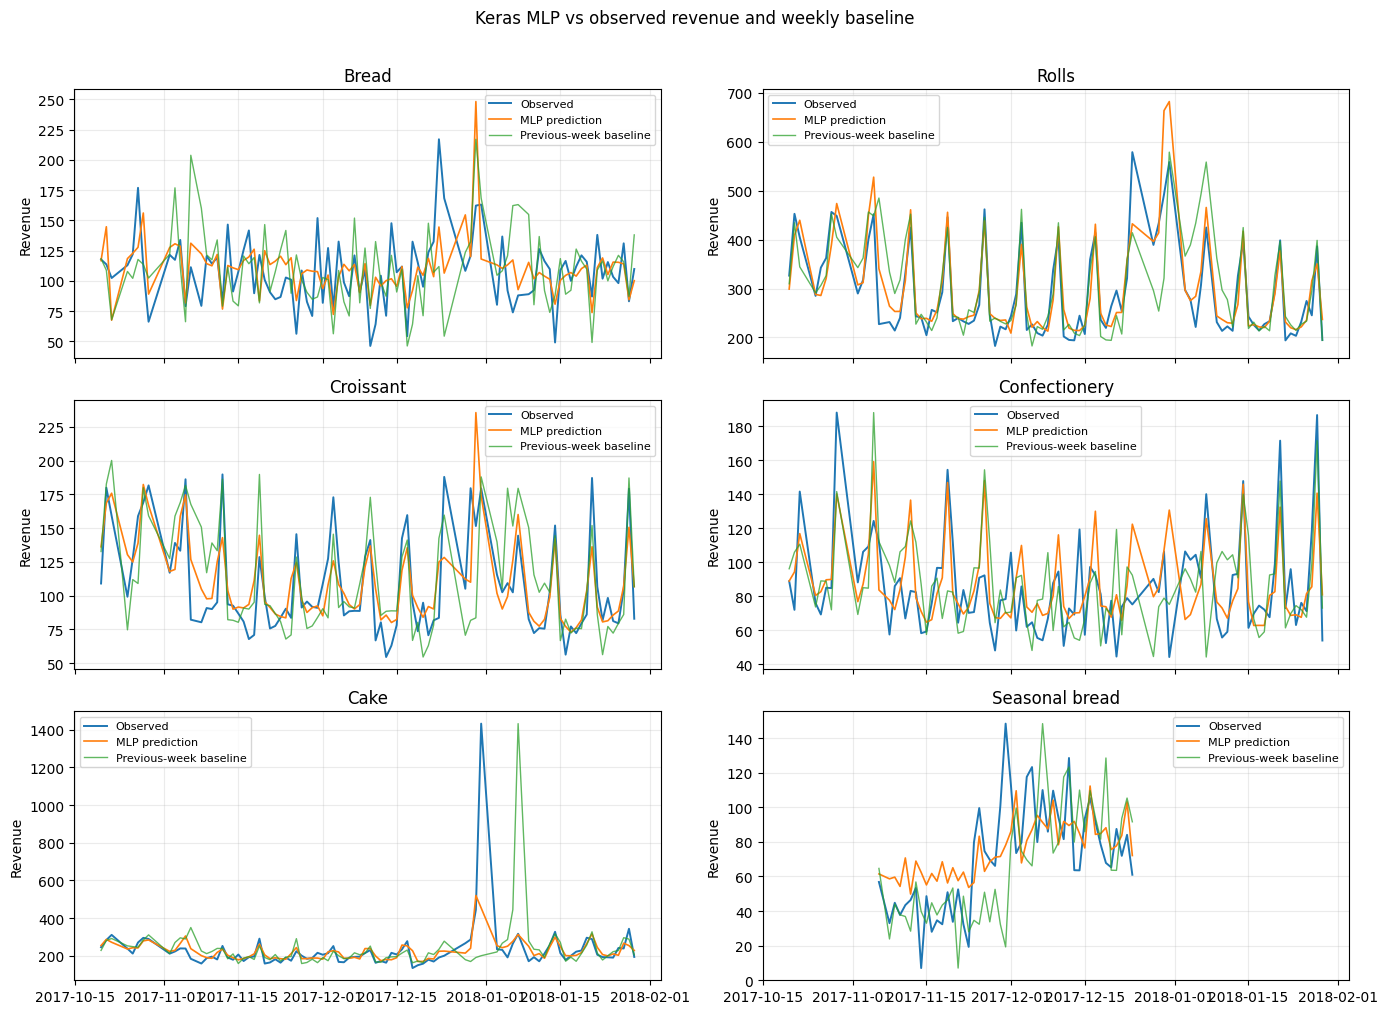

In [12]:
test_dates_for_plot = np.sort(mlp_test["Datum"].unique())
n_show = min(90, len(test_dates_for_plot))
selected_dates = test_dates_for_plot[:n_show]

plot_frame = mlp_test.copy()
plot_frame["MLP_prediction"] = mlp_test_prediction
plot_frame["Baseline_prediction"] = baseline_prediction
plot_frame = plot_frame[plot_frame["Datum"].isin(selected_dates)].sort_values("Datum")

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
for ax, (group_code, group_name) in zip(axes.ravel(), GROUP_NAMES.items()):
    group_frame = plot_frame[plot_frame["Warengruppe"] == group_code]
    ax.plot(group_frame["Datum"], group_frame["Umsatz"], label="Observed", linewidth=1.4)
    ax.plot(group_frame["Datum"], group_frame["MLP_prediction"], label="MLP prediction", linewidth=1.2)
    ax.plot(
        group_frame["Datum"],
        group_frame["Baseline_prediction"],
        label="Previous-week baseline",
        alpha=0.75,
        linewidth=1.0,
    )
    ax.set_title(group_name)
    ax.set_ylabel("Revenue")
    ax.legend(fontsize=8)

plt.suptitle("Keras MLP vs observed revenue and weekly baseline", y=1.01)
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح نمودار پیش‌بینی MLP

در هر پنل یک گروه محصول نمایش داده شده است: مقدار واقعی، پیش‌بینی MLP و خط مبنای فروش همان روز در هفته‌ی قبل. نمودار کمک می‌کند ببینیم مدل روند کلی را دنبال می‌کند یا نه. قله‌های ناگهانی ممکن است دشوار باشند؛ برای قضاوت نهایی، نمودار را همراه جدول MAE و RMSE و مقایسه با خط مبنا بخوانید.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱۱. پارامترهای مهم MLP؛ زیاد یا کم کردن چه اثری دارد؟

| پارامتر | مقدار شروع | افزایش مقدار | کاهش مقدار |
|---|---:|---|---|
| نورون‌های لایه‌های پنهان | ۶۴ و ۳۲ | ظرفیت بیشتر و امکان یادگیری روابط پیچیده‌تر؛ زمان آموزش و خطر بیش‌برازش بیشتر | مدل ساده‌تر؛ احتمال کم‌برازش |
| learning rate | ۰٫۰۰۱ | گام‌های بزرگ‌تر و یادگیری سریع‌تر؛ مقدار زیاد می‌تواند loss را نوسانی یا واگرا کند | آموزش آرام‌تر، اما احتمال کندی یا توقف زودهنگام |
| Dropout rate | ۰٫۲ | خاموش‌شدن نورون‌های بیشتر در زمان آموزش؛ منظم‌سازی قوی‌تر، ولی مقدار زیاد می‌تواند کم‌برازش ایجاد کند | منظم‌سازی ضعیف‌تر و خطر بیش‌برازش بیشتر |
| batch size | ۶۴ | گرادیان هموارتر و به‌روزرسانی‌های کمتر در هر epoch | به‌روزرسانی پرتعدادتر و معمولاً پرنوسان‌تر |
| تعداد epoch | حداکثر ۵۰ | فرصت یادگیری بیشتر؛ پس از نقطه‌ی مناسب ممکن است بیش‌برازش رخ دهد | ممکن است مدل هنوز الگوی مفید را یاد نگرفته باشد |
| patience | ۱۰ | اجازه می‌دهد مدل مدت بیشتری برای بهتر شدن validation تلاش کند | آموزش زودتر متوقف می‌شود |
| تعداد ویژگی‌های lag | ۳ ویژگی اصلی | اطلاعات تاریخی بیشتری وارد مدل می‌شود؛ ویژگی‌های اضافی ممکن است نویز ایجاد کنند | مدل ساده‌تر، اما ممکن است چرخه‌ی هفتگی را از دست بدهد |

**Batch Normalization** در این معماری بعد از هر لایه‌ی Dense قرار دارد. این لایه فعال‌سازی‌ها را در زمان آموزش بر اساس mini-batch نرمال می‌کند و در زمان پیش‌بینی از آمار ذخیره‌شده استفاده می‌کند.

### نتیجه‌ی خوب و بد MLP

- **خوب:** MAE و RMSE از baseline کمتر باشند؛ R² در بیشتر گروه‌ها مثبت باشد؛ پیش‌بینی‌ها روند واقعی را دنبال کنند.
- **ضعیف:** MAE یا RMSE از baseline بزرگ‌تر باشد یا R² منفی شود.
- **احتمال بیش‌برازش:** train loss کاهش یابد ولی validation loss بالا برود.
- **احتمال کم‌برازش:** هر دو خطا بالا و تقریباً ثابت بمانند.

افزودن دما یا رویدادها الزاماً مدل را بهتر نمی‌کند. عملکرد نسخه‌ی دارای این فایل‌ها را با نسخه‌ی بدون آن‌ها مقایسه کنید؛ فقط بهبود روی validation و test ارزشمند است.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

# بخش دوم: ماشین بولتزمن محدودشده (RBM)

## ۱۲. RBM چه کاری انجام می‌دهد؟

RBM در این تمرین فروش روز بعد را پیش‌بینی نمی‌کند. هدف آن پیدا کردن الگوهای پنهان میان گروه‌های محصول در یک پنجره‌ی ۱۴روزه است.

چون RBM برنولی ورودی دودویی می‌خواهد، درآمد هر گروه را به سه حالت ساده تبدیل می‌کنیم: **کم، متوسط و زیاد**. سپس این سه حالت را با one-hot نمایش می‌دهیم.

برای هر پنجره:

۱۴ روز × ۶ گروه × ۳ حالت = ۲۵۲ ویژگی قابل مشاهده

</div>

In [24]:

# Fit thresholds using training windows only.
train_window_values = X_windows[train_idx]
flat_train_values = train_window_values.reshape(-1, 6)

# Seasonal bread has many zero values, so it needs a separate encoding.
seasonal_idx = list(daily.columns).index("Seasonal bread")
regular_group_indices = [
    i for i, name in enumerate(daily.columns)
    if name != "Seasonal bread"
]

# Use two quantile thresholds for the five regular product groups.
regular_train_values = flat_train_values[:, regular_group_indices]

low_thresholds = np.quantile(
    regular_train_values, 1 / 3, axis=0
)
high_thresholds = np.quantile(
    regular_train_values, 2 / 3, axis=0
)

# For Seasonal bread:
# State 0 = no recorded sales
# State 1 = lower half of positive sales
# State 2 = upper half of positive sales
seasonal_positive_train = flat_train_values[:, seasonal_idx]
seasonal_positive_train = seasonal_positive_train[
    seasonal_positive_train > 0
]

if len(seasonal_positive_train) == 0:
    raise ValueError(
        "No positive Seasonal bread revenue found in training data."
    )

seasonal_positive_threshold = np.median(seasonal_positive_train)


def discretize_rbm_windows(windows):
    states = np.empty(windows.shape, dtype=np.int64)

    # Regular product groups: low, medium, high.
    for threshold_idx, group_idx in enumerate(regular_group_indices):
        values = windows[:, :, group_idx]

        states[:, :, group_idx] = np.where(
            values < low_thresholds[threshold_idx],
            0,
            np.where(
                values < high_thresholds[threshold_idx],
                1,
                2,
            ),
        )

    # Seasonal bread: no sales, low positive sales, high positive sales.
    seasonal_values = windows[:, :, seasonal_idx]

    states[:, :, seasonal_idx] = np.where(
        seasonal_values <= 0,
        0,
        np.where(
            seasonal_values <= seasonal_positive_threshold,
            1,
            2,
        ),
    )

    return states


def encode_rbm_windows(windows):
    states = discretize_rbm_windows(windows)

    # Convert the three states into one-hot vectors.
    return np.eye(3, dtype=np.float32)[states].reshape(
        len(windows), -1
    )


X_rbm_train = encode_rbm_windows(X_windows[train_idx])
X_rbm_val = encode_rbm_windows(X_windows[val_idx])
X_rbm_test = encode_rbm_windows(X_windows[test_idx])

print("Visible matrix:", X_rbm_train.shape)
print("Expected visible features:", WINDOW * 6 * 3)
print("Unique encoded values:", np.unique(X_rbm_train))

print(
    "Seasonal bread positive-sales threshold:",
    round(float(seasonal_positive_threshold), 2),
)

# Check how frequently each state occurs in the training data.
train_states = discretize_rbm_windows(X_windows[train_idx])

state_counts = pd.DataFrame(
    {
        "State 0": (train_states == 0).sum(axis=(0, 1)),
        "State 1": (train_states == 1).sum(axis=(0, 1)),
        "State 2": (train_states == 2).sum(axis=(0, 1)),
    },
    index=daily.columns,
)

display(state_counts)


Visible matrix: (746, 252)
Expected visible features: 252
Unique encoded values: [0. 1.]
Seasonal bread positive-sales threshold: 60.72


,State 0,State 1,State 2
Warengruppe,,,
Bread,3470,3489,3485
Rolls,3476,3484,3484
Croissant,3480,3478,3486
Confectionery,3471,3490,3483
Cake,3472,3479,3493
Seasonal bread,8950,749,745


<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱۳. آموزش RBM و مشاهده‌ی واحدهای پنهان

در این نسخه RBM فقط ۴ واحد پنهان دارد تا مدل ساده‌تر و تفسیر خروجی آن راحت‌تر باشد.

خروجی `transform` عددی بین صفر و یک است: هرچه مقدار بیشتر باشد، احتمال فعال‌شدن آن واحد برای آن پنجره بیشتر است. این عدد دقت پیش‌بینی یا احتمال فروش نیست.

</div>

In [51]:
RBM_HIDDEN_UNITS=12
rbm = BernoulliRBM(
    n_components=RBM_HIDDEN_UNITS,
    learning_rate=RBM_LEARNING_RATE,
    batch_size=RBM_BATCH_SIZE,
    n_iter=RBM_EPOCHS,
    verbose=False,
    random_state=SEED,
)
rbm.fit(X_rbm_train)

H_train = rbm.transform(X_rbm_train)
H_val = rbm.transform(X_rbm_val)
H_test = rbm.transform(X_rbm_test)

print("Visible units:", rbm.components_.shape[1])
print("Hidden units:", rbm.components_.shape[0])
print("Hidden activation range:", (round(H_val.min(), 3), round(H_val.max(), 3)))
print("Train mean pseudo-log-likelihood:", round(float(rbm.score_samples(X_rbm_train).mean()), 3))
print("Validation mean pseudo-log-likelihood:", round(float(rbm.score_samples(X_rbm_val).mean()), 3))

Visible units: 252
Hidden units: 12
Hidden activation range: (np.float32(0.0), np.float32(1.0))
Train mean pseudo-log-likelihood: -119.166
Validation mean pseudo-log-likelihood: -110.105


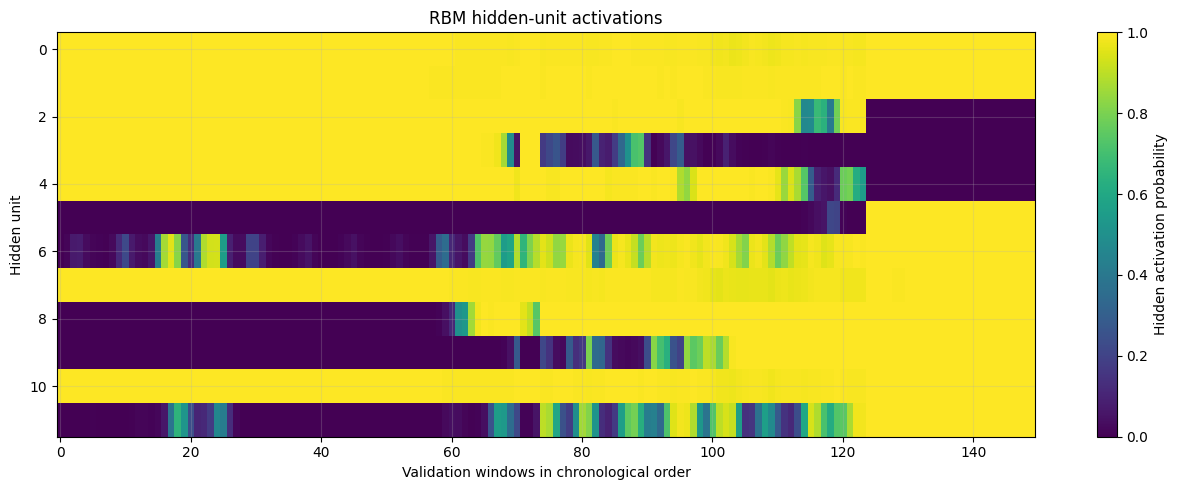

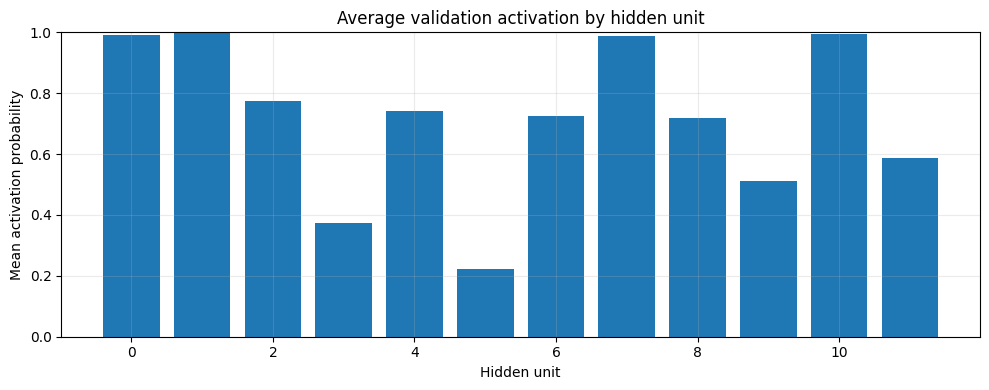

In [52]:
n_heat = min(150, len(H_val))
plt.figure(figsize=(13, 5))
plt.imshow(H_val[:n_heat].T, aspect="auto", interpolation="nearest", vmin=0, vmax=1, cmap="viridis")
plt.colorbar(label="Hidden activation probability")
plt.xlabel("Validation windows in chronological order")
plt.ylabel("Hidden unit")
plt.title("RBM hidden-unit activations")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.bar(np.arange(RBM_HIDDEN_UNITS), H_val.mean(axis=0))
plt.ylim(0, 1)
plt.xlabel("Hidden unit")
plt.ylabel("Mean activation probability")
plt.title("Average validation activation by hidden unit")
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح نمودارهای فعال‌سازی RBM

نقشه‌ی بالا نشان می‌دهد هر واحد پنهان در پنجره‌های مختلف چقدر فعال می‌شود. نمودار میله‌ای زیر آن میانگین فعال‌سازی هر واحد را نشان می‌دهد. در این نسخه فقط چهار واحد پنهان داریم؛ بنابراین بررسی تفاوت رفتار آن‌ها ساده‌تر است. واحدی که همیشه نزدیک صفر باشد معمولاً اطلاعات زیادی به نمایش یادگرفته‌شده اضافه نمی‌کند.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

### تفسیر نمودارهای فعال‌سازی RBM

- در نقشه‌ی رنگی، هر ردیف یک واحد پنهان و هر ستون یک پنجره‌ی اعتبارسنجی است.
- رنگ روشن‌تر یعنی احتمال فعال‌شدن آن واحد بیشتر است.
- نمودار میله‌ای، میانگین فعال‌سازی هر واحد را در کل پنجره‌های اعتبارسنجی نشان می‌دهد.
- بهتر است واحدها رفتارهای متفاوتی داشته باشند؛ اگر تقریباً همه‌ی واحدها همیشه صفر باشند، تعداد واحدها یا کیفیت ورودی را دوباره بررسی کنید.
- فعال‌نشدن برخی واحدها به‌تنهایی به معنی خراب بودن کل RBM نیست، ولی تعداد زیاد واحدهای غیرفعال نشانه‌ی پیچیدگی بیش از نیاز است.

</div>

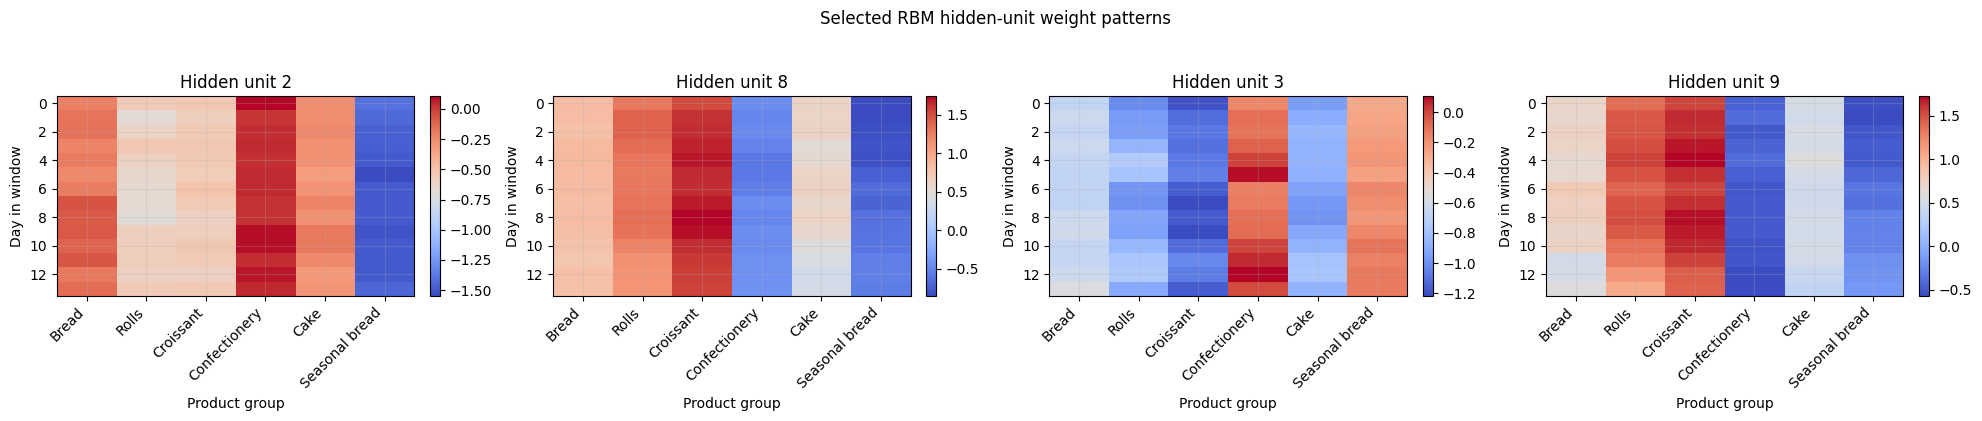

In [53]:
# Compare learned weights for the high and low one-hot states.
weight_tensor = rbm.components_.reshape(RBM_HIDDEN_UNITS, WINDOW, 6, 3)
high_minus_low = weight_tensor[:, :, :, 2] - weight_tensor[:, :, :, 0]
selected_units = np.argsort(H_train.std(axis=0))[-min(4, RBM_HIDDEN_UNITS):][::]

fig, axes = plt.subplots(1, len(selected_units), figsize=(5 * len(selected_units), 4), squeeze=False)
for ax, unit in zip(axes.ravel(), selected_units):
    image = ax.imshow(high_minus_low[unit], aspect="auto", cmap="coolwarm")
    ax.set_title(f"Hidden unit {unit}")
    ax.set_xlabel("Product group")
    ax.set_ylabel("Day in window")
    ax.set_xticks(range(6))
    ax.set_xticklabels(list(daily.columns), rotation=45, ha="right")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.suptitle("Selected RBM hidden-unit weight patterns", y=1.04)
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح نمودار وزن‌های RBM

هر تصویر مربوط به یک واحد پنهان است. محور افقی گروه محصول و محور عمودی روز داخل پنجره‌ی ۱۴روزه را نشان می‌دهد. رنگ مثبت یعنی حالت درآمد بالا نسبت به حالت پایین، آن واحد را بیشتر تحریک می‌کند؛ رنگ منفی اثر بازدارنده دارد. این وزن‌ها الگوی یادگرفته‌شده‌ی مدل هستند، نه یک قانون قطعی درباره‌ی فروش.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱۴. پارامترهای اصلی RBM

| پارامتر | اثر افزایش |
|---|---|
| تعداد واحدهای پنهان | مدل می‌تواند الگوهای بیشتری یاد بگیرد، اما تفسیر آن سخت‌تر می‌شود. |
| نرخ یادگیری | تغییر وزن‌ها سریع‌تر می‌شود؛ مقدار زیاد ممکن است آموزش را ناپایدار کند. |
| تعداد epoch | فرصت یادگیری بیشتر می‌شود؛ افزایش بیش از حد همیشه مفید نیست. |

برای بررسی نتیجه، به تنوع فعال‌سازی واحدها و الگوهای وزن‌ها نگاه کنید. RBM برچسب واقعی ندارد؛ بنابراین برای آن accuracy یا R² محاسبه نمی‌کنیم.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

# بخش سوم: خودرمزگذار (Autoencoder)

## ۱۵. Autoencoder چه کاری انجام می‌دهد؟

خودرمزگذار ورودی را به یک نمایش کوچک‌تر تبدیل می‌کند و سپس تلاش می‌کند همان ورودی را بازسازی کند.

در این تمرین پنجره‌ی ورودی ۸۴ مقدار دارد: ۱۴ روز × ۶ گروه محصول. لایه‌ی میانی ۱۲ واحد دارد و نقش گلوگاه یا bottleneck را بازی می‌کند.

</div>

In [17]:
ae_scaler = MinMaxScaler()
train_windows = X_windows[train_idx]
val_windows = X_windows[val_idx]
test_windows = X_windows[test_idx]

# Fit the scaler only on training-window values.
ae_scaler.fit(train_windows.reshape(-1, 6))

def scale_windows(windows):
    scaled = ae_scaler.transform(windows.reshape(-1, 6))
    return scaled.reshape(len(windows), -1)

AE_train = scale_windows(train_windows)
AE_val = scale_windows(val_windows)
AE_test = scale_windows(test_windows)

print("Autoencoder input shape:", AE_train.shape)
print("Scaled training range:", (round(AE_train.min(), 3), round(AE_train.max(), 3)))

Autoencoder input shape: (746, 84)
Scaled training range: (np.float64(0.0), np.float64(1.0))


<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱۶. آموزش Autoencoder و سنجش خطای بازسازی

در هر epoch شبکه یک پنجره را دریافت می‌کند و همان پنجره را به‌عنوان خروجی هدف می‌بیند. مدل منتخب با کمترین MSE اعتبارسنجی انتخاب می‌شود؛ بنابراین فقط به خطای بسیار پایین آموزش اکتفا نمی‌کنیم.

</div>

In [18]:
ae = MLPRegressor(
    hidden_layer_sizes=AE_HIDDEN_LAYERS,
    activation="relu",
    solver="adam",
    alpha=AE_ALPHA,
    batch_size=AE_BATCH_SIZE,
    learning_rate_init=AE_LEARNING_RATE,
    max_iter=1,
    random_state=SEED,
)

ae_train_loss, ae_val_loss = [], []
best_ae, best_ae_val, no_improvement = None, np.inf, 0

for epoch in range(1, AE_MAX_EPOCHS + 1):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        ae.partial_fit(AE_train, AE_train)

    train_reconstruction = ae.predict(AE_train)
    val_reconstruction = ae.predict(AE_val)
    train_loss = np.mean((AE_train - train_reconstruction) ** 2)
    val_loss = np.mean((AE_val - val_reconstruction) ** 2)
    ae_train_loss.append(float(train_loss))
    ae_val_loss.append(float(val_loss))

    if val_loss < best_ae_val - 1e-7:
        best_ae_val = val_loss
        best_ae = deepcopy(ae)
        best_ae_epoch = epoch
        no_improvement = 0
    else:
        no_improvement += 1

    if no_improvement >= AE_PATIENCE:
        break

ae = best_ae
print("Best autoencoder epoch:", best_ae_epoch)
print("Epochs executed:", len(ae_train_loss))
print("Best validation reconstruction MSE:", round(best_ae_val, 6))

Best autoencoder epoch: 300
Epochs executed: 300
Best validation reconstruction MSE: 0.003108


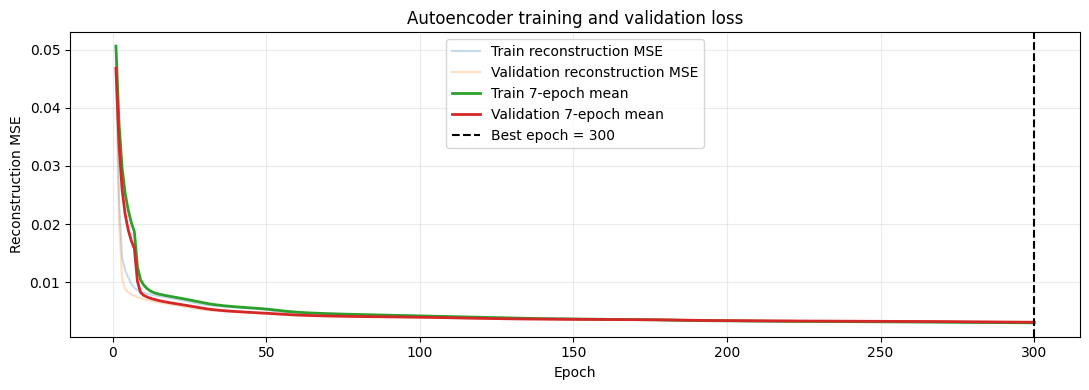

In [19]:
ae_epochs = np.arange(1, len(ae_train_loss) + 1)
plt.figure(figsize=(11, 4))
plt.plot(ae_epochs, ae_train_loss, alpha=0.25, label="Train reconstruction MSE")
plt.plot(ae_epochs, ae_val_loss, alpha=0.25, label="Validation reconstruction MSE")
plt.plot(ae_epochs, pd.Series(ae_train_loss).rolling(7, min_periods=1).mean(), linewidth=2, label="Train 7-epoch mean")
plt.plot(ae_epochs, pd.Series(ae_val_loss).rolling(7, min_periods=1).mean(), linewidth=2, label="Validation 7-epoch mean")
plt.axvline(best_ae_epoch, linestyle="--", color="black", label=f"Best epoch = {best_ae_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Reconstruction MSE")
plt.title("Autoencoder training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح نمودار خطای Autoencoder

خطوط کم‌رنگ مقدار خام خطا در هر epoch و خطوط پررنگ میانگین متحرک هفت epoch هستند. پایین آمدن train و validation نشان می‌دهد بازسازی بهتر شده است. فاصله‌ی زیاد و رو به افزایش بین آن‌ها می‌تواند نشانه‌ی بیش‌برازش باشد؛ در این حالت به validation توجه کنید، نه فقط train.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱۷. بررسی بازسازی و پنجره‌های غیرمعمول

خطای بازسازی، میانگین مربع اختلاف ۸۴ مقدار ورودی و خروجی بازسازی‌شده است.

- خطای کمتر یعنی مدل آن پنجره را بهتر بازسازی کرده است.
- خطای بیشتر یعنی آن پنجره برای مدل ناآشناتر بوده یا بازسازی آن دشوارتر بوده است.
- در این راهنما صدک ۹۵ خطای آموزش، آستانه‌ی اولیه‌ی بررسی است.

این آستانه تشخیص قطعی خرابی نیست. تعطیلات، فصل فروش یا تغییر واقعی تقاضا نیز می‌توانند خطای بازسازی را بالا ببرند.

</div>

Mean train reconstruction MSE: 0.003
Mean validation reconstruction MSE: 0.003108
Mean test reconstruction MSE: 0.003863
95th percentile of train error: 0.005681
Test windows above threshold: 39 of 197


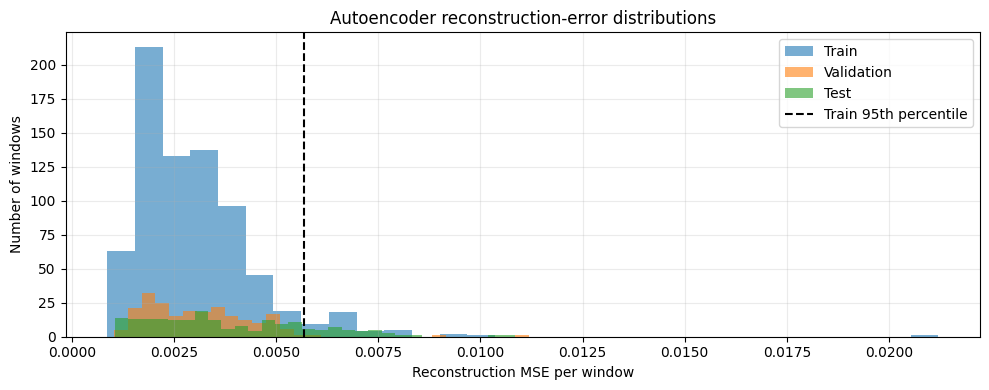

In [20]:
def reconstruction_errors(model, X):
    reconstructed = model.predict(X)
    errors = np.mean((X - reconstructed) ** 2, axis=1)
    return reconstructed, errors

AE_train_reconstructed, ae_train_errors = reconstruction_errors(ae, AE_train)
AE_val_reconstructed, ae_val_errors = reconstruction_errors(ae, AE_val)
AE_test_reconstructed, ae_test_errors = reconstruction_errors(ae, AE_test)

ae_threshold = float(np.quantile(ae_train_errors, 0.95))
print("Mean train reconstruction MSE:", round(float(ae_train_errors.mean()), 6))
print("Mean validation reconstruction MSE:", round(float(ae_val_errors.mean()), 6))
print("Mean test reconstruction MSE:", round(float(ae_test_errors.mean()), 6))
print("95th percentile of train error:", round(ae_threshold, 6))
print("Test windows above threshold:", int((ae_test_errors > ae_threshold).sum()), "of", len(ae_test_errors))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(ae_train_errors, bins=30, alpha=0.6, label="Train")
ax.hist(ae_val_errors, bins=30, alpha=0.6, label="Validation")
ax.hist(ae_test_errors, bins=30, alpha=0.6, label="Test")
ax.axvline(ae_threshold, color="black", linestyle="--", label="Train 95th percentile")
ax.set_xlabel("Reconstruction MSE per window")
ax.set_ylabel("Number of windows")
ax.set_title("Autoencoder reconstruction-error distributions")
ax.legend()
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح نمودار توزیع خطای بازسازی

هر ستون تعداد پنجره‌هایی را نشان می‌دهد که خطای بازسازی‌شان در آن بازه قرار گرفته است. خط‌چین، صدک ۹۵ خطای آموزش است. پنجره‌های آزمون در سمت راست این آستانه، مواردی هستند که بهتر است بررسی شوند؛ این نمودار به‌تنهایی وجود خرابی یا خطای واقعی را اثبات نمی‌کند.

</div>

C:\Users\Reza\AppData\Local\Temp\ipykernel_23372\1134012249.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


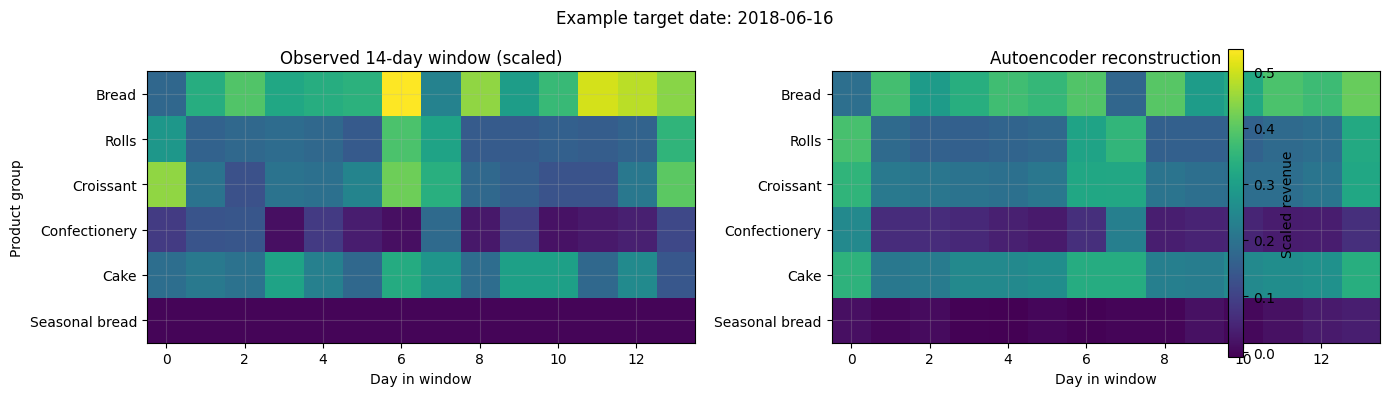

In [21]:
# Inspect a middle-of-the-distribution test window.
example_pos = int(np.argsort(ae_test_errors)[len(ae_test_errors) // 2])
actual_window = AE_test[example_pos].reshape(WINDOW, 6)
reconstructed_window = AE_test_reconstructed[example_pos].reshape(WINDOW, 6)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vmin = min(actual_window.min(), reconstructed_window.min())
vmax = max(actual_window.max(), reconstructed_window.max())
im0 = axes[0].imshow(actual_window.T, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax)
axes[0].set_title("Observed 14-day window (scaled)")
axes[0].set_xlabel("Day in window")
axes[0].set_ylabel("Product group")
axes[0].set_yticks(range(6))
axes[0].set_yticklabels(list(daily.columns))
im1 = axes[1].imshow(reconstructed_window.T, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax)
axes[1].set_title("Autoencoder reconstruction")
axes[1].set_xlabel("Day in window")
axes[1].set_yticks(range(6))
axes[1].set_yticklabels(list(daily.columns))
fig.colorbar(im1, ax=axes, fraction=0.025, pad=0.02, label="Scaled revenue")
fig.suptitle(f"Example target date: {target_dates[test_idx[example_pos]].date()}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح مقایسه‌ی ورودی و بازسازی

در تصویر سمت چپ پنجره‌ی واقعیِ مقیاس‌بندی‌شده و در سمت راست بازسازی مدل دیده می‌شود. هر ردیف یک گروه محصول و هر ستون یک روز است. انتظار نداریم همه‌ی قله‌ها دقیقاً تکرار شوند؛ مهم این است که مدل سطح و الگوی کلی پنجره را تا حد مناسبی بازسازی کند.

</div>

In [22]:
top_count = min(10, len(ae_test_errors))
top_positions = np.argsort(ae_test_errors)[-top_count:][::-1]
unusual_windows = pd.DataFrame({
    "target_date": target_dates[test_idx][top_positions],
    "reconstruction_MSE": ae_test_errors[top_positions],
    "above_train_95pct_threshold": ae_test_errors[top_positions] > ae_threshold,
})
display(unusual_windows)

,target_date,reconstruction_MSE,above_train_95pct_threshold
0,2018-03-29,0.010848,True
1,2018-04-13,0.010520,True
2,2018-07-20,0.008322,True
3,2018-06-29,0.008210,True
4,2018-06-28,0.007637,True
5,2018-06-27,0.007631,True
6,2018-07-22,0.007630,True
7,2017-12-24,0.007490,True
8,2018-06-24,0.007373,True
9,2018-07-24,0.007367,True


<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱۸. مشاهده‌ی فضای فشرده‌ی Autoencoder

برای هر پنجره، لایه‌ی bottleneck یک بردار ۱۲بعدی می‌سازد. این بردار خلاصه‌ای فشرده از الگوی ۱۴ روزه است؛ آن را نمایش یادگرفته‌شده بدانید، نه برچسب آماده‌ی نوع روز.

</div>

Bottleneck representation shape: (197, 12)


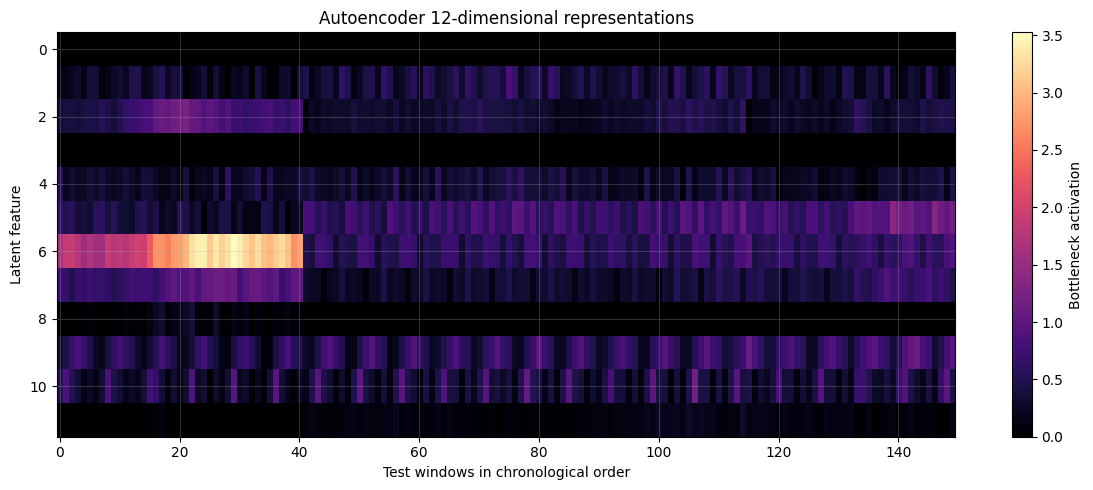

In [23]:
def extract_bottleneck(model, X):
    activations = X
    # The first two hidden layers form the encoder: 32 -> 12.
    for layer_index in range(2):
        activations = activations @ model.coefs_[layer_index] + model.intercepts_[layer_index]
        activations = np.maximum(activations, 0)
    return activations

latent_test = extract_bottleneck(ae, AE_test)
print("Bottleneck representation shape:", latent_test.shape)

plt.figure(figsize=(12, 5))
plt.imshow(latent_test[:min(150, len(latent_test))].T, aspect="auto", interpolation="nearest", cmap="magma")
plt.colorbar(label="Bottleneck activation")
plt.xlabel("Test windows in chronological order")
plt.ylabel("Latent feature")
plt.title("Autoencoder 12-dimensional representations")
plt.tight_layout()
plt.show()

<div dir="rtl" style="direction: rtl; text-align: right;">

### توضیح نمایش bottleneck

هر ردیف یکی از ۱۲ ویژگی فشرده و هر ستون یک پنجره‌ی آزمون است. رنگ روشن‌تر یعنی مقدار فعال‌سازی آن ویژگی بیشتر است. این ویژگی‌ها نام یا برچسب مشخصی مثل «روز شلوغ» ندارند؛ آن‌ها خلاصه‌هایی هستند که مدل هنگام آموزش یاد گرفته است.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## ۱۹. پارامترهای اصلی Autoencoder

| پارامتر | اثر افزایش |
|---|---|
| اندازه‌ی bottleneck | بازسازی آسان‌تر می‌شود، اما فشرده‌سازی کمتر خواهد بود. |
| اندازه‌ی لایه‌های پنهان | ظرفیت مدل بیشتر می‌شود؛ خطر بیش‌برازش نیز می‌تواند بیشتر شود. |
| نرخ یادگیری | آموزش سریع‌تر می‌شود؛ مقدار زیاد ممکن است loss را نوسانی کند. |
| تعداد epoch | فرصت یادگیری بیشتر می‌شود؛ نمودار validation نشان می‌دهد چه زمانی بهبود متوقف شده است. |

خطای بازسازی پایین برای کیفیت بازسازی خوب است. اما برای پیدا کردن پنجره‌های غیرمعمول، خطای بالا ارزش بررسی بیشتری دارد. این دو برداشت را با هم اشتباه نگیرید.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

# ۲۰. جمع‌بندی

| مدل | ورودی | خروجی |
|---|---|---|
| MLP | فروش روزهای قبل و ویژگی‌های تقویمی | پیش‌بینی درآمد یک گروه محصول |
| RBM | پنجره‌ی ۱۴روزه با سه سطح درآمد | احتمال فعال‌شدن واحدهای پنهان |
| Autoencoder | پنجره‌ی ۱۴روزه با ۸۴ مقدار | پنجره‌ی بازسازی‌شده و خطای بازسازی |

**نکته‌های مهم:**

۱. `Umsatz` درآمد فروش است، نه تعداد محصولات.
۲. نبودن ردیف برای نان فصلی در این تمرین به‌صورت صفر در نظر گرفته می‌شود؛ این فرض فقط برای همین گروه فصلی است.
۳. سایر تاریخ‌های گمشده را خودکار صفر نمی‌کنیم؛ پنجره‌هایی که داده‌ی ناقص دارند وارد RBM و Autoencoder نمی‌شوند.
۴. پنجره‌های آموزش، اعتبارسنجی و آزمون جدا ساخته می‌شوند تا داده‌ی مشترک بین این سه بخش وجود نداشته باشد.
۵. خطای بازسازی بالا فقط یک علامت برای بررسی است و به‌تنهایی ثابت نمی‌کند داده خراب است.

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

## منابع و مستندات

- منبع داده: [Kaggle – Bakery Sales Prediction Summer 2024](https://www.kaggle.com/competitions/bakery-sales-prediction-summer-24/data)
- mirror عمومی فایل فروش: [Godfaada – Bakery Sales Prediction](https://github.com/Godfaada/Bakery_Sales_Prediction)
- مدل الهام‌بخش: [Clarabri – best_model_neural_net.ipynb](https://github.com/clarabri/bakery-sales-prediction/blob/main/3_Model/best_model_neural_net.ipynb)
- [Keras Sequential model](https://keras.io/guides/sequential_model/)
- [Keras BatchNormalization](https://keras.io/api/layers/normalization_layers/batch_normalization/)
- [Keras Dropout](https://keras.io/api/layers/regularization_layers/dropout/)
- [scikit-learn BernoulliRBM](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.BernoulliRBM.html)
- [مدل‌های شبکه‌ی عصبی بدون نظارت](https://scikit-learn.org/stable/modules/neural_networks_unsupervised.html)

</div>